<a href="https://colab.research.google.com/github/sim07hamdani/FDM5-3P-Travaux/blob/main/notebooks/04_matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/04_matplotlib.ipynb)

# Python pour la physique — 4. Matplotlib : tracer des graphiques

> 💡 **Astuce**
>
> **Rappel** : exécutez les cellules dans l'ordre avec **Maj + Entrée**. Les solutions des exercices sont masquées dans des cellules « Solution » : essayez d'abord par vous-même !

In [1]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

Exécution dans Google Colab


# Introduction

[Matplotlib](https://matplotlib.org/) est probablement la bibliothèque Python la plus utilisée pour les graphiques 2D. Elle offre à la fois un moyen rapide de visualiser des données et la possibilité de produire des figures de qualité publication dans de nombreux formats.

Dans un carnet Jupyter ou Google Colab, **les figures s'insèrent directement sous la cellule** qui les produit : il n'y a rien à activer.


> 📝 **Note**
>
> Dans un terminal IPython sur votre ordinateur, on activerait le mode interactif avec la commande magique `%matplotlib`. Ce n'est pas nécessaire dans Colab.

## pyplot

*pyplot* est une interface procédurale à la bibliothèque orientée objet de Matplotlib. Elle est calquée sur Matlab™ : la plupart des commandes de pyplot ont un équivalent Matlab avec des arguments similaires.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Tracé simple

Dans cette section, nous voulons tracer les fonctions cosinus et sinus sur le même graphique. À partir des réglages par défaut, nous allons enrichir la figure pas à pas pour l'embellir.

La première étape consiste à calculer les données :

In [3]:
X = np.linspace(-np.pi, np.pi, 256)
C, S = np.cos(X), np.sin(X)

`X` est un tableau NumPy de 256 valeurs allant de $-\pi$ à $+\pi$ (inclus). `C` est le cosinus (256 valeurs) et `S` le sinus (256 valeurs).

## Tracé avec les réglages par défaut

Matplotlib est livré avec un ensemble de réglages par défaut qui permettent de personnaliser toutes sortes de propriétés : taille de la figure et résolution (dpi), épaisseur, couleur et style des lignes, axes, grille, polices, etc.

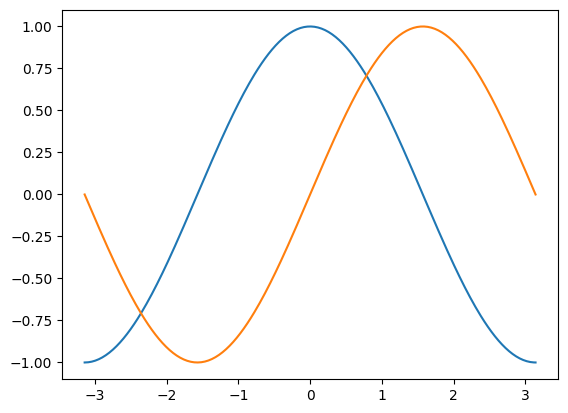

In [4]:
plt.plot(X, C)
plt.plot(X, S);

> 📝 **Note**
>
> Remarquez le point-virgule (`;`) à la fin de la dernière ligne : il évite que Jupyter n'affiche la valeur de retour de la dernière expression (un objet `Line2D`). Il n'a aucun autre effet.

## Les réglages par défaut, explicités

Dans le code ci-dessous, nous avons explicité (et commenté) tous les réglages de figure qui influencent l'apparence du tracé. Les valeurs sont celles par défaut, mais vous pouvez maintenant les modifier pour explorer leur effet.

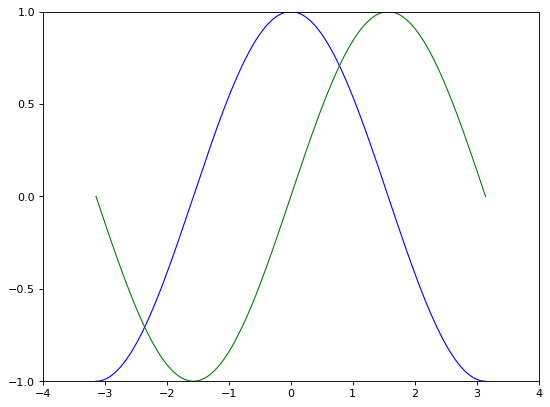

In [5]:
# Crée une figure de 8x6 pouces, 80 points par pouce
plt.figure(figsize=(8, 6), dpi=80)

# Crée un sous-graphique dans une grille 1x1
plt.subplot(1, 1, 1)

X = np.linspace(-np.pi, np.pi, 256)
C, S = np.cos(X), np.sin(X)

# Cosinus : ligne continue bleue d'épaisseur 1 (pixel)
plt.plot(X, C, color="blue", linewidth=1.0, linestyle="-")

# Sinus : ligne continue verte d'épaisseur 1 (pixel)
plt.plot(X, S, color="green", linewidth=1.0, linestyle="-")

# Limites de l'axe x
plt.xlim(-4.0, 4.0)

# Graduations de l'axe x
plt.xticks(np.linspace(-4, 4, 9))

# Limites de l'axe y
plt.ylim(-1.0, 1.0)

# Graduations de l'axe y
plt.yticks(np.linspace(-1, 1, 5));

# On pourrait aussi enregistrer la figure à 72 points par pouce avec :
# plt.savefig("exercice_2.png", dpi=72)

## Changer les couleurs et les épaisseurs de ligne

Premier objectif : cosinus en bleu, sinus en rouge, et des lignes un peu plus épaisses. Nous modifions aussi un peu la taille de la figure pour la rendre plus horizontale.

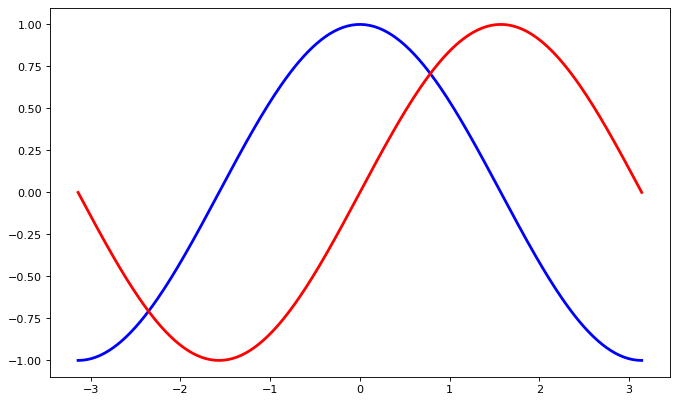

In [6]:
plt.figure(figsize=(10, 6), dpi=80)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-");

## Fixer les limites

Les limites actuelles sont un peu trop serrées : nous voulons laisser de la place pour bien voir tous les points.

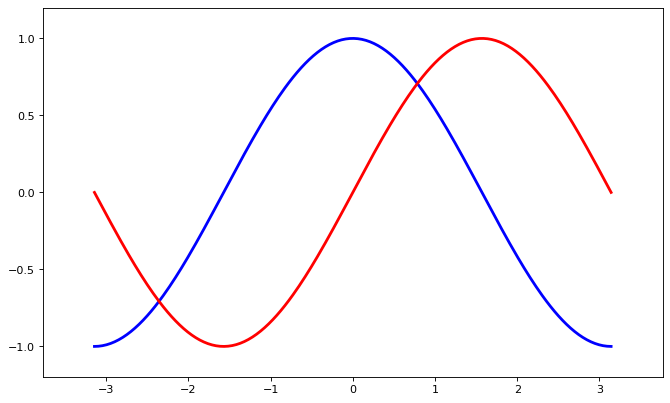

In [7]:
plt.figure(figsize=(10, 6), dpi=80)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-")

# Limites des axes
plt.xlim(X.min() * 1.2, X.max() * 1.2)
plt.ylim(C.min() * 1.2, C.max() * 1.2);

## Fixer les graduations (*ticks*)

Les graduations actuelles ne sont pas idéales car elles n'affichent pas les valeurs intéressantes ($\pm \pi$, $\pm \frac{\pi}{2}$). Nous allons les changer pour n'afficher que celles-ci.

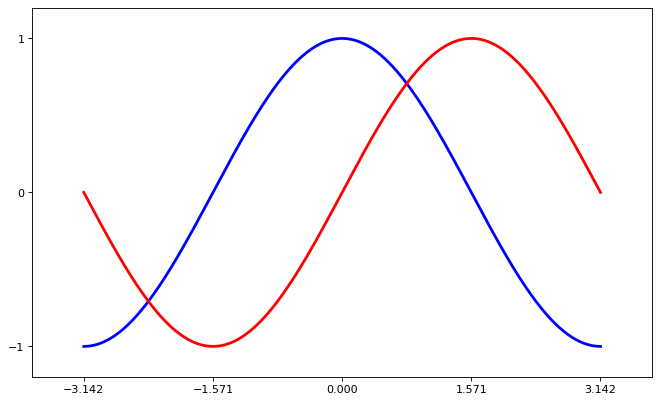

In [8]:
plt.figure(figsize=(10, 6), dpi=80)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-")
plt.xlim(X.min() * 1.2, X.max() * 1.2)
plt.ylim(C.min() * 1.2, C.max() * 1.2)

plt.xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
plt.yticks([-1, 0, +1]);

## Fixer les étiquettes de graduation

Les graduations sont bien placées, mais leur étiquette n'est pas très explicite. On pourrait deviner que 3,142 est $\pi$, mais il vaut mieux l'écrire. Quand on fixe les valeurs des graduations, on peut fournir en second argument la liste des étiquettes correspondantes. Nous utilisons ici LaTeX pour un joli rendu.

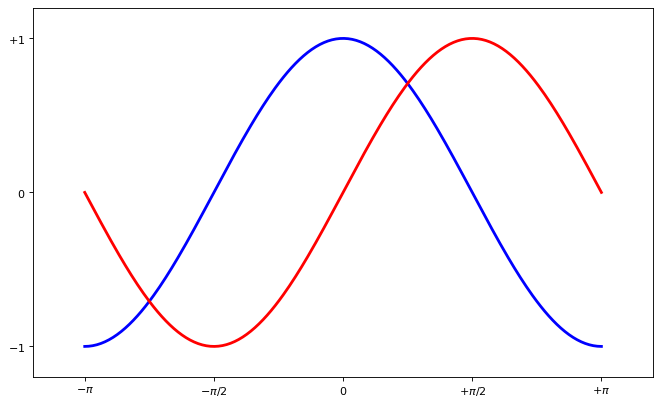

In [9]:
plt.figure(figsize=(10, 6), dpi=80)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-")
plt.xlim(X.min() * 1.2, X.max() * 1.2)
plt.ylim(C.min() * 1.2, C.max() * 1.2)

plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$+\pi/2$', r'$+\pi$'])
plt.yticks([-1, 0, +1],
           [r'$-1$', r'$0$', r'$+1$']);

## Déplacer les axes (*spines*)

Les *spines* sont les lignes qui relient les graduations et délimitent la zone des données. Elles peuvent être placées à des positions arbitraires ; jusqu'ici, elles étaient sur le bord. Nous voulons les mettre au centre. Il y en a quatre (haut, bas, gauche, droite) : nous supprimons celles du haut et de droite en leur donnant la couleur « none », et nous déplaçons celles du bas et de gauche à la coordonnée 0.

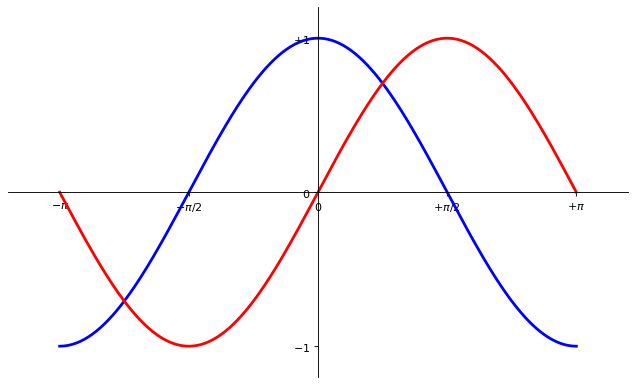

In [10]:
plt.figure(figsize=(10, 6), dpi=80)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-")
plt.xlim(X.min() * 1.2, X.max() * 1.2)
plt.ylim(C.min() * 1.2, C.max() * 1.2)
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$+\pi/2$', r'$+\pi$'])
plt.yticks([-1, 0, +1], [r'$-1$', r'$0$', r'$+1$'])

ax = plt.gca()  # gca = « get current axis » (récupérer l'axe courant)
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.xaxis.set_ticks_position('bottom')
ax.spines['bottom'].set_position(('data', 0))
ax.yaxis.set_ticks_position('left')
ax.spines['left'].set_position(('data', 0));

## Ajouter une légende

Ajoutons une légende en haut à gauche. Il suffit d'ajouter l'argument `label` aux commandes `plot` (il sera utilisé dans le cadre de la légende), puis d'appeler `legend`.

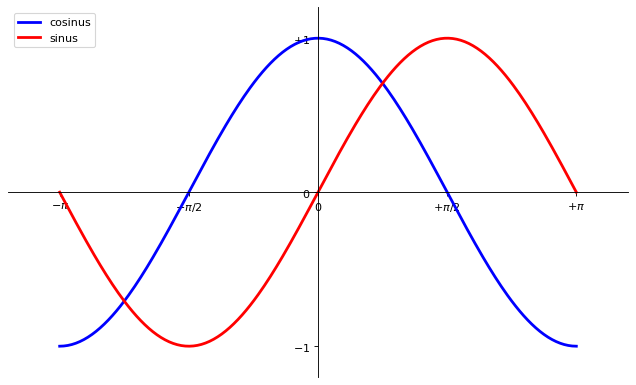

In [11]:
plt.figure(figsize=(10, 6), dpi=80)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-", label="cosinus")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-", label="sinus")
plt.xlim(X.min() * 1.2, X.max() * 1.2)
plt.ylim(C.min() * 1.2, C.max() * 1.2)
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$+\pi/2$', r'$+\pi$'])
plt.yticks([-1, 0, +1], [r'$-1$', r'$0$', r'$+1$'])
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_position(('data', 0))
ax.spines['left'].set_position(('data', 0))

plt.legend(loc='upper left');

## Annoter des points

Annotons quelques points intéressants avec la commande `annotate`. Nous choisissons la valeur $t = 2\pi/3$ et nous voulons annoter le sinus et le cosinus : nous traçons un marqueur sur la courbe ainsi qu'une ligne verticale en pointillés, puis nous utilisons `annotate` pour afficher du texte avec une flèche.

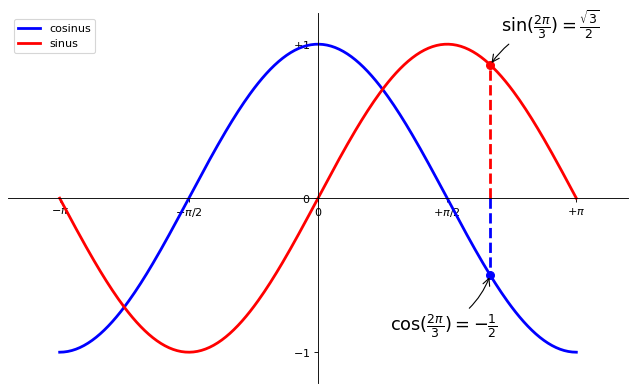

In [12]:
plt.figure(figsize=(10, 6), dpi=80)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-", label="cosinus")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-", label="sinus")
plt.xlim(X.min() * 1.2, X.max() * 1.2)
plt.ylim(C.min() * 1.2, C.max() * 1.2)
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$+\pi/2$', r'$+\pi$'])
plt.yticks([-1, 0, +1], [r'$-1$', r'$0$', r'$+1$'])
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_position(('data', 0))
ax.spines['left'].set_position(('data', 0))
plt.legend(loc='upper left')

t = 2 * np.pi / 3
plt.plot([t, t], [0, np.cos(t)], color='blue', linewidth=2.5, linestyle="--")
plt.scatter([t], [np.cos(t)], 50, color='blue')
plt.annotate(r'$\sin(\frac{2\pi}{3})=\frac{\sqrt{3}}{2}$',
             xy=(t, np.sin(t)), xycoords='data',
             xytext=(+10, +30), textcoords='offset points', fontsize=16,
             arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=.2"))

plt.plot([t, t], [0, np.sin(t)], color='red', linewidth=2.5, linestyle="--")
plt.scatter([t], [np.sin(t)], 50, color='red')
plt.annotate(r'$\cos(\frac{2\pi}{3})=-\frac{1}{2}$',
             xy=(t, np.cos(t)), xycoords='data',
             xytext=(-90, -50), textcoords='offset points', fontsize=16,
             arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=.2"));

> **Exercice**
>
> Reprenez la figure précédente et tracez à la place l'**oscillation amortie** d'un système masse-ressort :
>
> $$x(t) = A\, e^{-t/\tau} \cos(2\pi f t)$$
>
> avec $A = 1\ \text{cm}$, $\tau = 2\ \text{s}$, $f = 1{,}5\ \text{Hz}$, pour $t \in [0, 6]$ s. Ajoutez les titres d'axes avec leurs unités, une légende, et l'enveloppe $\pm A e^{-t/\tau}$ en pointillés.

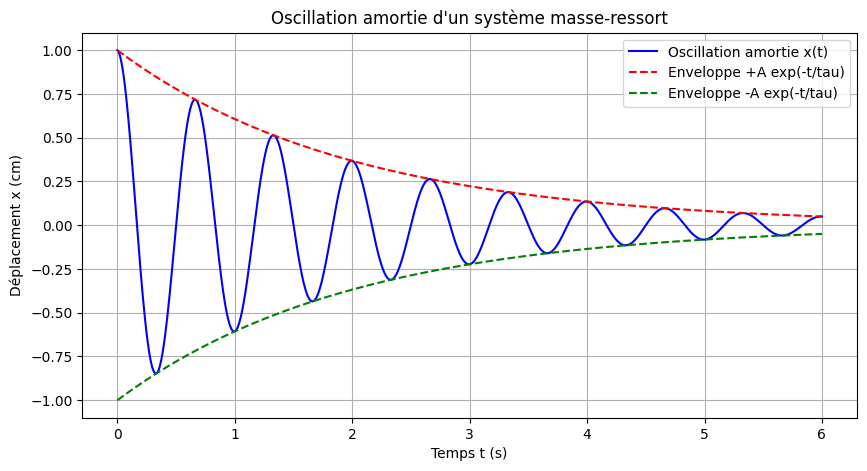

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Données de l'exercice
A = 1.0       # Amplitude initiale (cm)
tau = 2.0     # Temps caractéristique (s)
f = 1.5       # Fréquence (Hz)

# Temps entre 0 et 6 secondes
t = np.linspace(0, 6, 1000)

# Oscillation amortie
x = A * np.exp(-t/tau) * np.cos(2*np.pi*f*t)

# Enveloppes positive et négative
enveloppe = A * np.exp(-t/tau)

# Tracé du graphique
plt.figure(figsize=(10, 5))

plt.plot(t, x, color="blue",
         label="Oscillation amortie x(t)")

plt.plot(t, enveloppe, "r--",
         label="Enveloppe +A exp(-t/tau)")

plt.plot(t, -enveloppe, "g--",
         label="Enveloppe -A exp(-t/tau)")

# Titres et unités
plt.title("Oscillation amortie d'un système masse-ressort")
plt.xlabel("Temps t (s)")
plt.ylabel("Déplacement x (cm)")

# Grille et légende
plt.grid(True)
plt.legend()
plt.show()

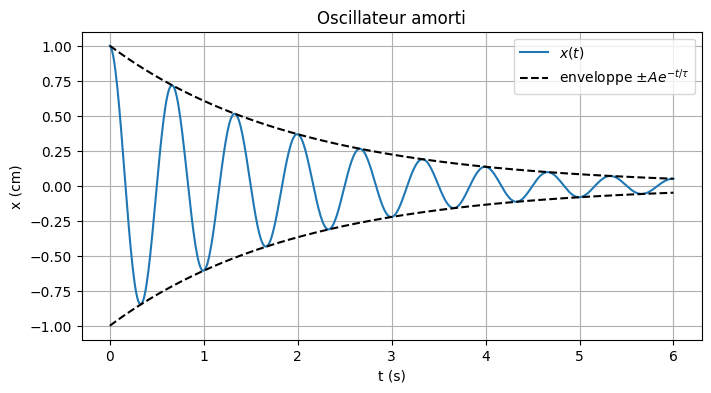

In [13]:
#@title Solution { display-mode: "form" }
A, tau, f = 1.0, 2.0, 1.5
t = np.linspace(0, 6, 600)
x = A * np.exp(-t / tau) * np.cos(2 * np.pi * f * t)
enveloppe = A * np.exp(-t / tau)

plt.figure(figsize=(8, 4))
plt.plot(t, x, label=r"$x(t)$")
plt.plot(t, enveloppe, 'k--', label=r"enveloppe $\pm A e^{-t/\tau}$")
plt.plot(t, -enveloppe, 'k--')
plt.xlabel("t (s)")
plt.ylabel("x (cm)")
plt.title("Oscillateur amorti")
plt.legend()
plt.grid(True)
plt.show()

# Figures, sous-graphiques, axes et graduations

Jusqu'ici, nous avons utilisé l'interface simple de *pyplot*, qui agit sur la « figure courante ». Pour des figures plus élaborées, il est préférable d'utiliser l'interface **orientée objet** : on crée explicitement une figure `fig` et un ou plusieurs axes `ax`.

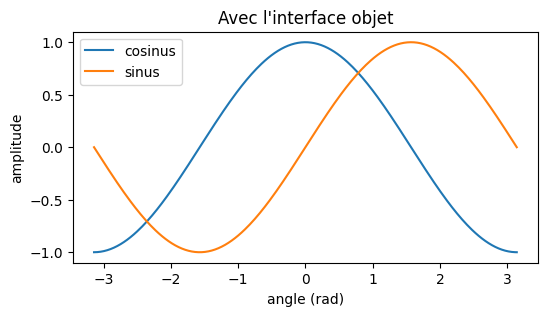

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(X, C, label="cosinus")
ax.plot(X, S, label="sinus")
ax.set_xlabel("angle (rad)")
ax.set_ylabel("amplitude")
ax.set_title("Avec l'interface objet")
ax.legend()
plt.show()

## Figures

Une *figure* est la fenêtre dans l'interface utilisateur. Les figures sont numérotées à partir de 1. Voici les principaux paramètres :

| Argument    | Valeur par défaut | Description                                |
| ----------- | ----------------- | ------------------------------------------ |
| `num`       | `1`               | numéro de la figure                        |
| `figsize`   | `[6.4, 4.8]`      | taille de la figure (largeur, hauteur) en pouces |
| `dpi`       | `100`             | résolution en points par pouce             |
| `facecolor` | `'white'`         | couleur de fond                            |

## Sous-graphiques (*subplots*)

Avec les sous-graphiques, vous placez des graphiques dans une grille régulière. Il faut préciser le nombre de lignes et de colonnes :

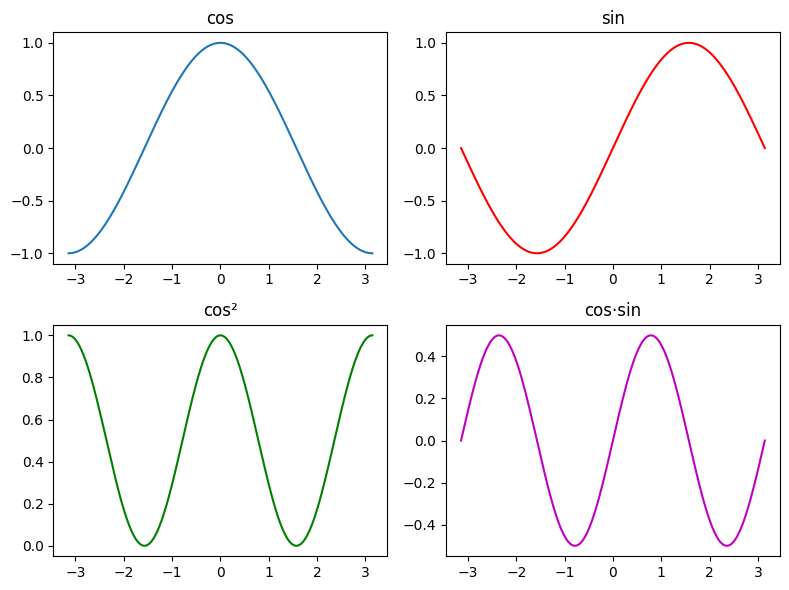

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
axes[0, 0].plot(X, C);          axes[0, 0].set_title("cos")
axes[0, 1].plot(X, S, 'r');     axes[0, 1].set_title("sin")
axes[1, 0].plot(X, C**2, 'g');  axes[1, 0].set_title("cos²")
axes[1, 1].plot(X, C*S, 'm');   axes[1, 1].set_title("cos·sin")
fig.tight_layout()   # évite que les titres se chevauchent
plt.show()

Avec `sharex=True` et `sharey=True`, les sous-graphiques partagent leurs axes, ce qui facilite la comparaison :

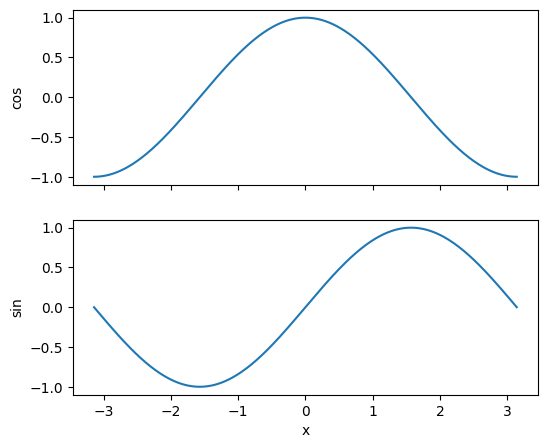

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 5))
ax1.plot(X, C);  ax1.set_ylabel("cos")
ax2.plot(X, S);  ax2.set_ylabel("sin"); ax2.set_xlabel("x")
plt.show()

## Axes

Les *axes* ressemblent aux sous-graphiques, mais permettent de placer un graphique **n'importe où** dans la figure, avec des coordonnées relatives (de 0 à 1). On peut ainsi faire un graphique dans le graphique :

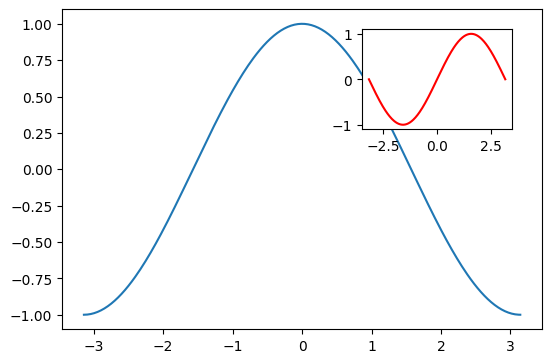

In [18]:
fig = plt.figure(figsize=(6, 4))
ax_grand = fig.add_axes([0.1, 0.1, 0.8, 0.8])      # [gauche, bas, largeur, hauteur]
ax_grand.plot(X, C)
ax_petit = fig.add_axes([0.6, 0.6, 0.25, 0.25])
ax_petit.plot(X, S, 'r')
plt.show()

## Graduations (*ticks*)

Les graduations bien formatées sont essentielles à la qualité d'une figure. Matplotlib offre un système très complet. Vous avez déjà vu `plt.xticks` ; en interface objet, on utilise `ax.set_xticks` et `ax.set_xticklabels`. On peut aussi utiliser des *locators* (`matplotlib.ticker`) pour des graduations régulières, logarithmiques, etc.

# Autres types de graphiques

## Courbes avec points de mesure et barres d'erreur

En physique expérimentale, on trace presque toujours des **points de mesure avec leurs incertitudes**. On utilise pour cela `errorbar` :

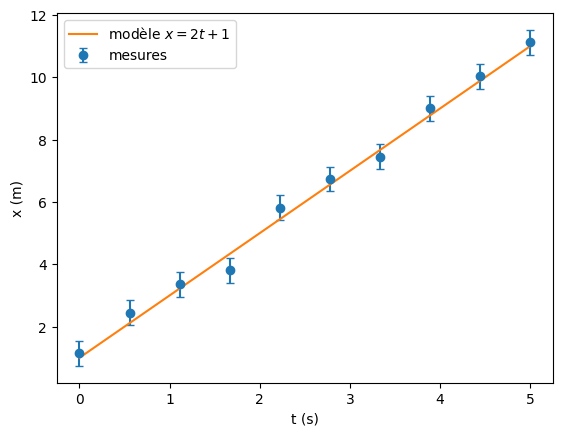

In [33]:
rng = np.random.default_rng(1)
t_mes = np.linspace(0, 5, 10)
x_mes = 2.0 * t_mes + 1.0 + rng.normal(0, 0.4, t_mes.size)   # mesures bruitées
u_x = 0.4 * np.ones_like(t_mes)                              # incertitudes

plt.errorbar(t_mes, x_mes, yerr=u_x, fmt='o', capsize=3, label="mesures")
plt.plot(t_mes, 2.0 * t_mes + 1.0, '-', label="modèle $x = 2t + 1$")
plt.xlabel("t (s)")
plt.ylabel("x (m)")
plt.legend()
plt.show()

## Échelles logarithmiques

Pour les lois de puissance, les exponentielles ou les diagrammes de Bode, on utilise des échelles logarithmiques : `plt.loglog`, `plt.semilogx`, `plt.semilogy` (ou `ax.set_xscale('log')`).

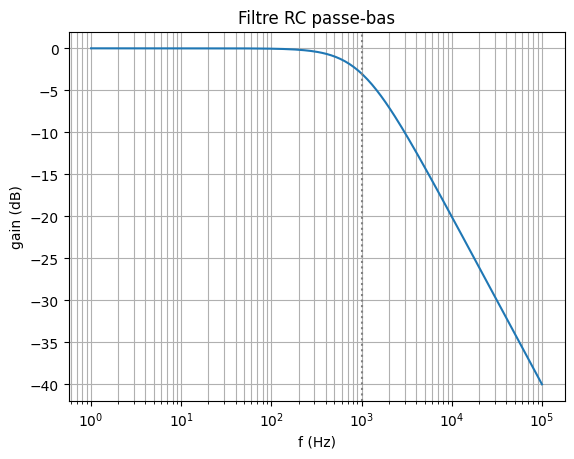

In [34]:
f = np.logspace(0, 5, 200)          # fréquences de 1 Hz à 100 kHz
fc = 1000.0                          # fréquence de coupure d'un filtre RC (Hz)
H = 1 / np.sqrt(1 + (f / fc)**2)     # gain d'un filtre passe-bas
plt.semilogx(f, 20 * np.log10(H))
plt.axvline(fc, color='gray', linestyle=':')
plt.xlabel("f (Hz)")
plt.ylabel("gain (dB)")
plt.title("Filtre RC passe-bas")
plt.grid(True, which='both')
plt.show()

## Nuage de points (*scatter*)

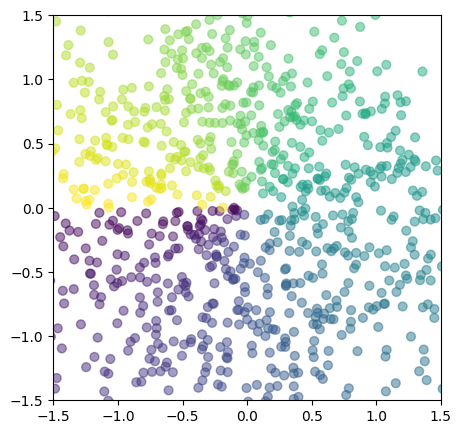

In [35]:
rng = np.random.default_rng(0)
n = 1024
X_ = rng.normal(0, 1, n)
Y_ = rng.normal(0, 1, n)
T = np.arctan2(Y_, X_)      # couleur selon l'angle

plt.figure(figsize=(5, 5))
plt.scatter(X_, Y_, s=40, c=T, alpha=.5)
plt.xlim(-1.5, 1.5); plt.ylim(-1.5, 1.5)
plt.show()

## Diagramme en barres et histogramme

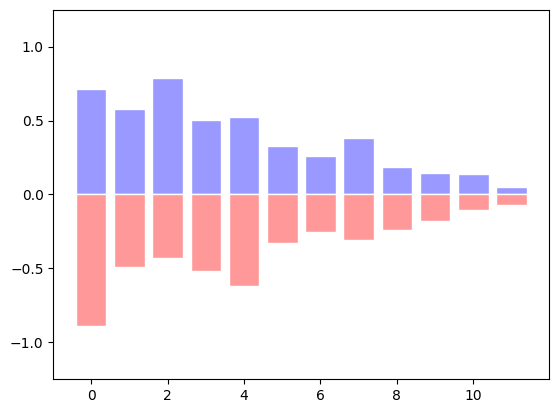

In [36]:
n = 12
Xb = np.arange(n)
Y1 = (1 - Xb / float(n)) * (0.5 + 0.5 * rng.uniform(size=n))
Y2 = (1 - Xb / float(n)) * (0.5 + 0.5 * rng.uniform(size=n))

plt.bar(Xb, +Y1, facecolor='#9999ff', edgecolor='white')
plt.bar(Xb, -Y2, facecolor='#ff9999', edgecolor='white')
plt.ylim(-1.25, +1.25)
plt.show()

L'**histogramme** est essentiel pour visualiser la distribution de mesures répétées :

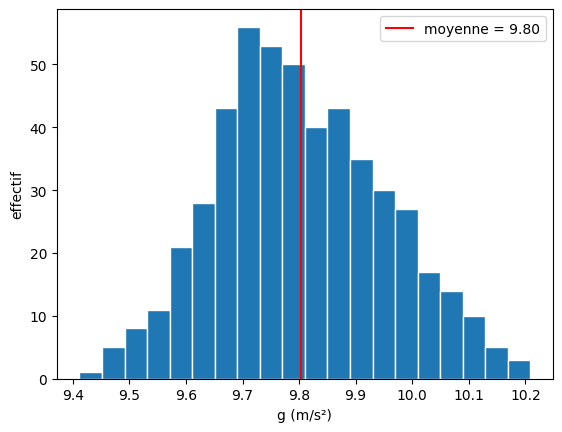

In [37]:
mesures = rng.normal(loc=9.81, scale=0.15, size=500)   # 500 mesures de g
plt.hist(mesures, bins=20, edgecolor='white')
plt.axvline(mesures.mean(), color='r', label=f"moyenne = {mesures.mean():.2f}")
plt.xlabel("g (m/s²)")
plt.ylabel("effectif")
plt.legend()
plt.show()

## Lignes de niveau (*contour*) et cartes (*imshow*)

On affiche une fonction de deux variables, comme un potentiel ou une intensité d'interférence, avec `contour`, `contourf` ou `imshow` :

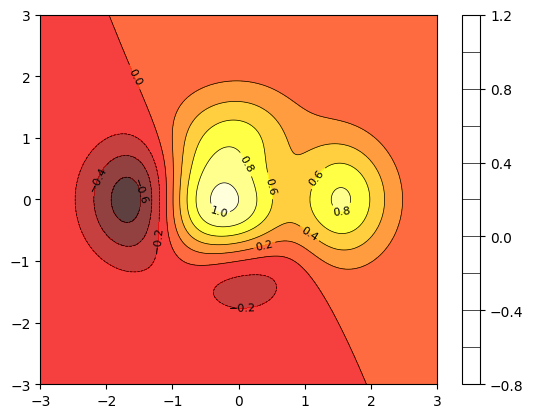

In [38]:
def f(x, y):
    return (1 - x / 2 + x**5 + y**3) * np.exp(-x**2 - y**2)

n = 256
x = np.linspace(-3, 3, n)
y = np.linspace(-3, 3, n)
XX, YY = np.meshgrid(x, y)

plt.contourf(XX, YY, f(XX, YY), 8, alpha=.75, cmap='hot')
cs = plt.contour(XX, YY, f(XX, YY), 8, colors='black', linewidths=.5)
plt.clabel(cs, inline=1, fontsize=8)
plt.colorbar()
plt.show()

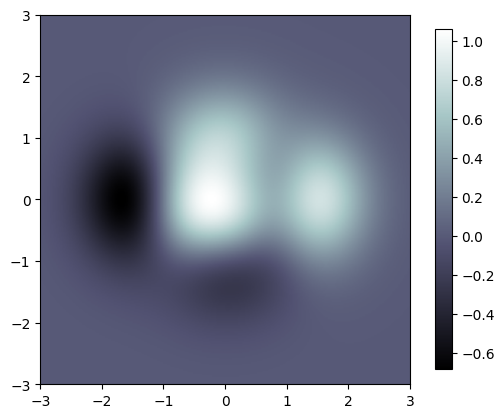

In [39]:
plt.imshow(f(XX, YY), cmap='bone', origin='lower', extent=[-3, 3, -3, 3])
plt.colorbar(shrink=.92)
plt.show()

## Champ de vecteurs (*quiver*)

Très utile pour représenter un champ électrique ou une vitesse :

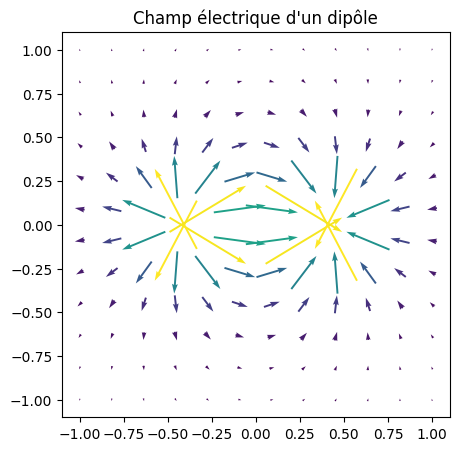

In [40]:
n = 12
x = np.linspace(-1, 1, n)
XX, YY = np.meshgrid(x, x)
# Champ d'un dipôle (modèle simplifié) : deux charges +1 et -1
def champ(q, x0, y0):
    dx, dy = XX - x0, YY - y0
    r3 = (dx**2 + dy**2 + 0.02)**1.5
    return q * dx / r3, q * dy / r3
Ex1, Ey1 = champ(+1, -0.4, 0)
Ex2, Ey2 = champ(-1, +0.4, 0)
Ex, Ey = Ex1 + Ex2, Ey1 + Ey2

plt.figure(figsize=(5, 5))
plt.quiver(XX, YY, Ex, Ey, np.hypot(Ex, Ey), pivot='mid', cmap='viridis')
plt.title("Champ électrique d'un dipôle")
plt.show()

## Coordonnées polaires

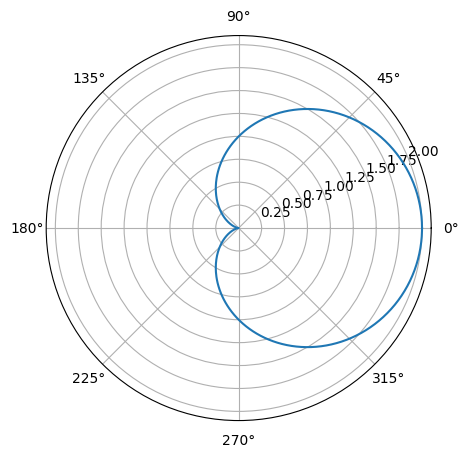

In [41]:
plt.figure(figsize=(5, 5))
ax = plt.subplot(1, 1, 1, projection='polar')
theta = np.linspace(0, 2 * np.pi, 400)
ax.plot(theta, 1 + np.cos(theta))      # cardioïde
plt.show()

## Tracés 3D

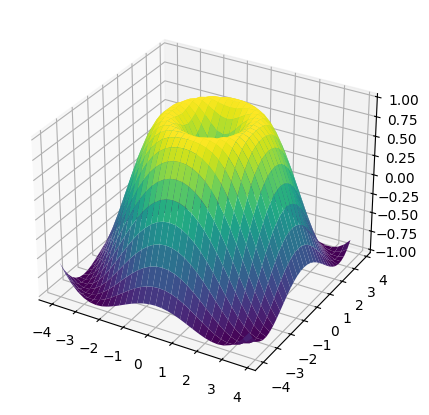

In [42]:
from mpl_toolkits.mplot3d import Axes3D  # noqa : nécessaire sur d'anciennes versions

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection='3d')
X3 = np.arange(-4, 4, 0.25)
Y3 = np.arange(-4, 4, 0.25)
X3, Y3 = np.meshgrid(X3, Y3)
R = np.sqrt(X3**2 + Y3**2)
Z = np.sin(R)

ax.plot_surface(X3, Y3, Z, rstride=1, cstride=1, cmap='viridis')
plt.show()

> 📝 **Note**
>
> Pour des figures 3D interactives (rotation à la souris), Colab propose aussi la bibliothèque **Plotly** (`import plotly.express as px`), préinstallée.

# Enregistrer une figure

Pour inclure vos figures dans un compte rendu, enregistrez-les avec `savefig`, en PNG (images) ou PDF/SVG (vectoriel, qualité publication) :

['.config', 'cosinus.pdf', 'cosinus.png', 'sample_data']

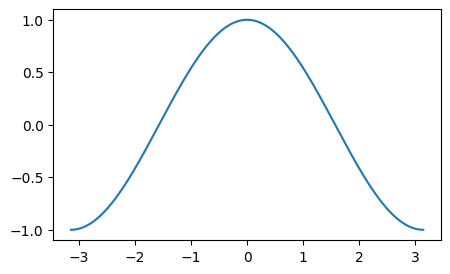

In [30]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(X, C)
fig.savefig("cosinus.png", dpi=200, bbox_inches='tight')
fig.savefig("cosinus.pdf", bbox_inches='tight')
import os
os.listdir('.')

> 💡 **Astuce**
>
> **Avec Google Drive** : pour enregistrer directement dans votre Drive, montez-le avec `from google.colab import drive; drive.mount('/content/drive')`, puis enregistrez dans `/content/drive/MyDrive/...`. Sinon, téléchargez le fichier sur votre ordinateur avec :
>
> ```python
> from google.colab import files
> files.download("cosinus.png")
> ```

# Pour aller plus loin

- La [galerie Matplotlib](https://matplotlib.org/gallery.html) : des centaines d'exemples avec leur code. C'est le meilleur moyen de trouver comment réaliser un graphique.
- Les [tutoriels officiels](https://matplotlib.org/stable/tutorials/index.html).
- **Seaborn** (`import seaborn as sns`) : graphiques statistiques plus esthétiques, basés sur Matplotlib.
- **Plotly** : graphiques interactifs.

# Aide-mémoire

| Je veux…                         | Commande                                         |
| -------------------------------- | ------------------------------------------------ |
| tracer une courbe                | `plt.plot(x, y)`                                 |
| tracer des points                | `plt.plot(x, y, 'o')` ou `plt.scatter(x, y)`     |
| points avec incertitudes         | `plt.errorbar(x, y, yerr=u, fmt='o')`            |
| titres et unités                 | `plt.xlabel("t (s)")`, `plt.ylabel(...)`, `plt.title(...)` |
| légende                          | `label=...` dans `plot`, puis `plt.legend()`     |
| quadrillage                      | `plt.grid(True)`                                 |
| échelle log                      | `plt.loglog`, `plt.semilogx`, `plt.semilogy`     |
| plusieurs graphiques             | `fig, axes = plt.subplots(2, 2)`                 |
| image / carte 2D                 | `plt.imshow(tableau)` + `plt.colorbar()`         |
| histogramme                      | `plt.hist(donnees, bins=20)`                     |
| enregistrer                      | `plt.savefig("fig.png", dpi=200)`                |


> **Exercice de synthèse : mouvement d'un projectile**
>
> Reprenez le projectile du carnet 3 (angle $\theta = 45^\circ$, $v_0 = 20$ m/s). Dans une même figure à deux sous-graphiques, tracez :
>
> 1. à gauche, les trajectoires $y(x)$ pour plusieurs angles (15°, 30°, 45°, 60°, 75°), avec une légende ;
> 2. à droite, la portée en fonction de l'angle (de 0° à 90°), avec le maximum marqué d'un point rouge.

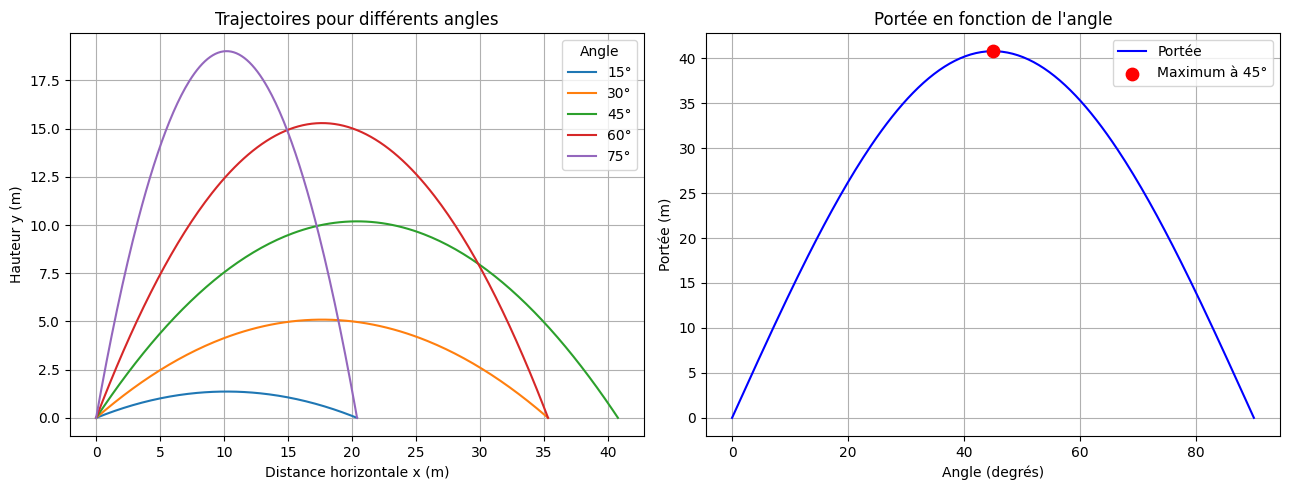

Angle optimal : 45°
Portée maximale : 40.77 m


In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Données du problème
v0 = 20       # Vitesse initiale (m/s)
g = 9.81      # Accélération de la pesanteur (m/s²)

# Création d'une figure avec 2 sous-graphiques
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# ==========================================
# 1. À GAUCHE : Trajectoires du projectile
# ==========================================

angles = [15, 30, 45, 60, 75]

for angle in angles:
    theta = np.deg2rad(angle)

    # Durée totale du vol
    T = 2 * v0 * np.sin(theta) / g

    # 200 instants entre 0 et T
    t = np.linspace(0, T, 200)

    # Positions du projectile
    x = v0 * np.cos(theta) * t
    y = v0 * np.sin(theta) * t - 0.5 * g * t**2

    # Tracer la trajectoire
    ax[0].plot(x, y, label=f"{angle}°")

ax[0].set_title("Trajectoires pour différents angles")
ax[0].set_xlabel("Distance horizontale x (m)")
ax[0].set_ylabel("Hauteur y (m)")
ax[0].grid(True)
ax[0].legend(title="Angle")

# ==========================================
# 2. À DROITE : Portée en fonction de l'angle
# ==========================================

angles_deg = np.linspace(0, 90, 200)
angles_rad = np.deg2rad(angles_deg)

# Formule de la portée
portee = (v0**2 / g) * np.sin(2 * angles_rad)

# Maximum de la portée
indice_max = np.argmax(portee)
angle_max = angles_deg[indice_max]
portee_max = portee[indice_max]

# Tracer la courbe
ax[1].plot(angles_deg, portee,
           color="blue", label="Portée")

# Marquer le maximum par un point rouge
ax[1].scatter(45, v0**2/g,
              color="red", s=80, zorder=5,
              label="Maximum à 45°")

ax[1].set_title("Portée en fonction de l'angle")
ax[1].set_xlabel("Angle (degrés)")
ax[1].set_ylabel("Portée (m)")
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()

# Affichage du maximum théorique
print("Angle optimal : 45°")
print("Portée maximale :", round(v0**2/g, 2), "m")

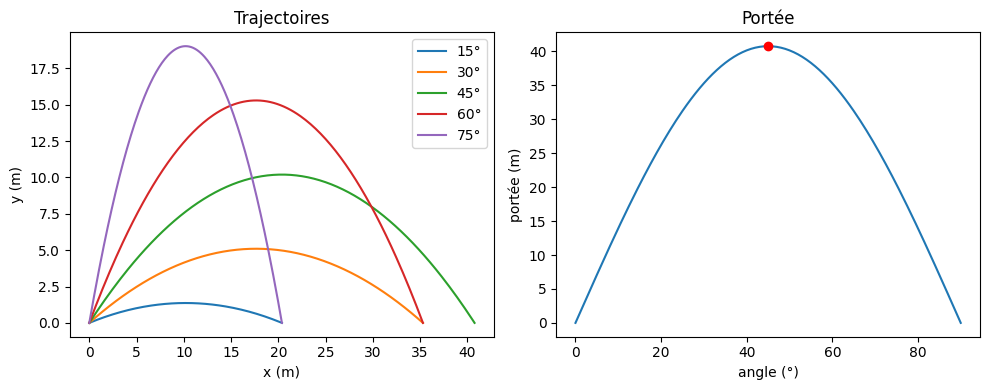

In [32]:
#@title Solution { display-mode: "form" }
g, v0 = 9.81, 20.0
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

for angle in [15, 30, 45, 60, 75]:
    th = np.radians(angle)
    T = 2 * v0 * np.sin(th) / g
    t = np.linspace(0, T, 200)
    ax1.plot(v0 * np.cos(th) * t, v0 * np.sin(th) * t - 0.5 * g * t**2,
             label=f"{angle}°")
ax1.set_xlabel("x (m)"); ax1.set_ylabel("y (m)"); ax1.legend()
ax1.set_title("Trajectoires")

angles = np.linspace(0, 90, 181)
portee = v0**2 * np.sin(2 * np.radians(angles)) / g
ax2.plot(angles, portee)
ax2.plot(angles[portee.argmax()], portee.max(), 'ro')
ax2.set_xlabel("angle (°)"); ax2.set_ylabel("portée (m)")
ax2.set_title("Portée")
fig.tight_layout()
plt.show()

---

*Fin du carnet 4. Suite : carnet 5 — SciPy.*